# DS2002 · Critique and Redesign

**Studio — 2026-11-11 · Fall 2026**  
**Class time:** 45 minutes

---

## Critique, then rebuild twice

Charts do not get good in one pass. Today you take three bad charts through two iterations each: fix the mechanics first, then sharpen the argument.

That split is deliberate. Iteration one is checkable — labels, sorting, units, layout. Iteration two is the judgment part: what is this chart actually claiming, and is the claim the most useful one available in the data?

Bring your midterm charts to the last section. We will run the rubric on real work.

### The rubric

Score any chart out of 6. This is the same rubric used on both project presentations, so learn to run it on your own work.

| # | Criterion | Fails when |
|---|---|---|
| 1 | Title states a finding | Title names the columns |
| 2 | Axes labeled with units | "Revenue" with no currency; no axis label |
| 3 | Right chart for the question | Pie for comparison; bars for a trend |
| 4 | Honest scale | Truncated bar axis; unnormalized comparison |
| 5 | Readable | Overlapping labels, clipped text, unsorted categories |
| 6 | No wasted ink | Decoration, redundant legends, chart junk |

Run this cell so we all score the same way.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

CRITERIA = ['title states a finding', 'axes labeled with units',
            'right chart for the question', 'honest scale',
            'readable', 'no wasted ink']

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total

### Chart 1 — the pie chart

Here is the chart that shows up in roughly a third of student decks.

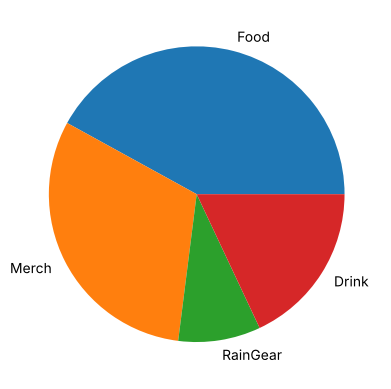

In [2]:
cats = ['Food', 'Merch', 'RainGear', 'Drink']
vals = [4200, 3100, 900, 1800]
plt.pie(vals, labels=cats)
plt.show()

**TODO:** score it. Then say in a comment which two slices you cannot rank by eye — that is the concrete cost of the chart type, not a matter of taste.

In [3]:
score(title=False,       # no title at all, let alone a finding
      axes=False,        # no unit anywhere: dollars? units sold?
      chart_type=False,  # pie for a ranking/comparison question
      scale=True,        # shares of a whole, nothing truncated
      readable=False,    # slices in data order, no values, Drink and RainGear squeezed together
      ink=True)          # no decoration to strip

# Ambiguous: Food vs Merch. They are the two big wedges (42% vs 31% of $10,000), they start at
# different angles, and the eye cannot compare angles/areas reliably: without the numbers you
# cannot say by how much Food leads, and side by side at a glance they read as roughly "both big".
# That is the cost of the chart type: a pie asks the reader to compare angles, a bar compares
# lengths on a common baseline, which people do accurately.

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 2/6


2

**Iteration 1 — fix the mechanics.**

**TODO:** rebuild as a sorted horizontal bar chart. Title, axis label with unit, top and right spines removed, value labels on the bars, `tight_layout()`. Do not worry yet about whether the message is the best one available.

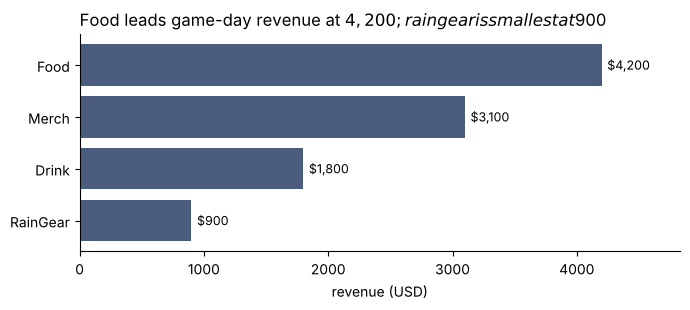

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [4]:
rev = pd.Series(vals, index=cats).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(rev.index, rev.values, color='#4a5d7e')
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in rev.values], padding=4, fontsize=9)
ax.set_title(f'Food leads game-day revenue at ${rev.max():,.0f}; rain gear is smallest at ${rev.min():,.0f}',
             loc='left', fontsize=12)
ax.set_xlabel('revenue (USD)')
ax.set_xlim(0, rev.max() * 1.15)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

**Iteration 2 — sharpen the argument.**

The mechanical version probably says something like "Food leads revenue." True, and not very useful — food leads revenue at every game.

**TODO:** the more interesting fact is in this second frame: rain gear is tiny in total but enormous relative to how often it sells. Build a chart that makes *that* the claim, and write the title as the claim.

In [5]:
detail = pd.DataFrame({
    'category': ['Food', 'Merch', 'RainGear', 'Drink'],
    'revenue': [4200, 3100, 900, 1800],
    'games_sold_in': [6, 6, 2, 6],   # rain gear only moves on wet days
}).set_index('category')
detail['revenue_per_game'] = detail['revenue'] / detail['games_sold_in']
detail

,revenue,games_sold_in,revenue_per_game
category,,,
Food,4200,6,700.000000
Merch,3100,6,516.666667
RainGear,900,2,450.000000
Drink,1800,6,300.000000


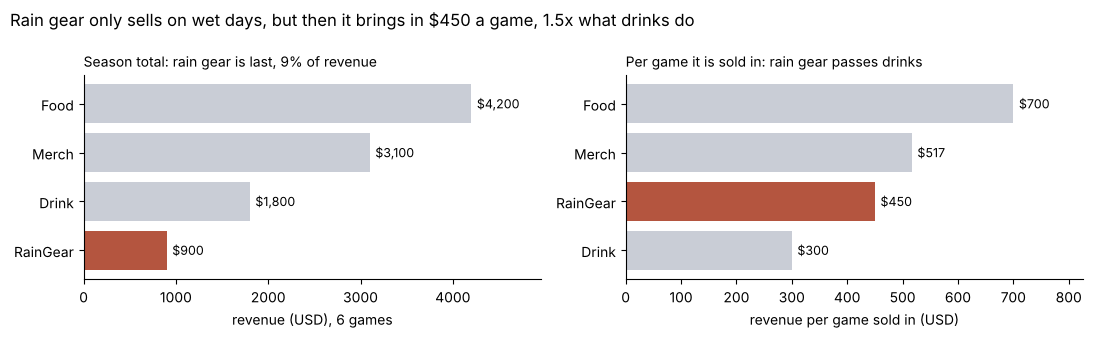

In [6]:
total = detail['revenue'].sort_values()
per_game = detail['revenue_per_game'].sort_values()
highlight = lambda idx: ['#b4553f' if c == 'RainGear' else '#c9cdd6' for c in idx]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
b0 = axes[0].barh(total.index, total.values, color=highlight(total.index))
axes[0].bar_label(b0, labels=[f'${v:,.0f}' for v in total.values], padding=4, fontsize=9)
axes[0].set_title('Season total: rain gear is last, 9% of revenue', loc='left', fontsize=10)
axes[0].set_xlabel('revenue (USD), 6 games')
axes[0].set_xlim(0, total.max() * 1.18)

b1 = axes[1].barh(per_game.index, per_game.values, color=highlight(per_game.index))
axes[1].bar_label(b1, labels=[f'${v:,.0f}' for v in per_game.values], padding=4, fontsize=9)
axes[1].set_title('Per game it is sold in: rain gear passes drinks', loc='left', fontsize=10)
axes[1].set_xlabel('revenue per game sold in (USD)')
axes[1].set_xlim(0, per_game.max() * 1.18)
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

rg, dr = detail.loc['RainGear', 'revenue_per_game'], detail.loc['Drink', 'revenue_per_game']
fig.suptitle(f'Rain gear only sells on wet days, but then it brings in ${rg:,.0f} a game, '
             f'{rg / dr:.1f}x what drinks do', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

### Chart 2 — the misleading axis

**TODO:** score this one, name the specific problem, and rebuild it honestly. Then answer: is the difference between these zones worth acting on?

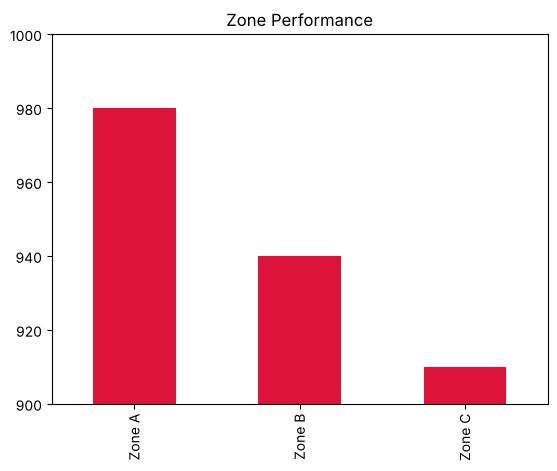

In [7]:
zones = pd.Series({'Zone A': 980, 'Zone B': 940, 'Zone C': 910})
zones.plot(kind='bar', color='crimson')
plt.ylim(900, 1000)
plt.title('Zone Performance')
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
PASS - right chart for the question
FAIL - honest scale
PASS - readable
FAIL - no wasted ink

score: 2/6


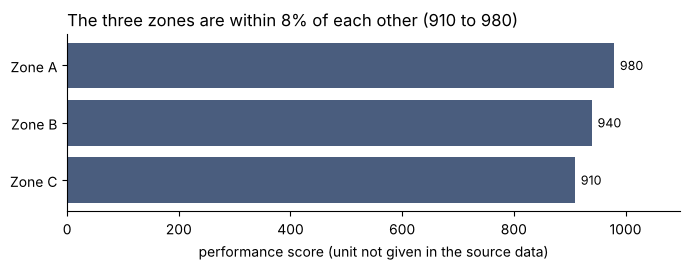

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [8]:
score(title=False,       # "Zone Performance" names a topic, not a finding
      axes=False,        # no y label, no unit (orders? dollars?)
      chart_type=True,   # bars are right for comparing three zones
      scale=False,       # y-axis starts at 900, on a bar chart
      readable=True,     # three short labels, already in descending order
      ink=False)         # crimson implies alarm/meaning it does not carry; no value labels to make up for it

# The specific problem: ylim(900, 1000) truncates the bars. Zone A's bar is drawn 8x as tall as
# Zone C's (80 vs 10 above the cutoff) when A is only 7.7% higher (980 vs 910).
z = zones.sort_values()
fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(z.index, z.values, color='#4a5d7e')
ax.bar_label(bars, labels=[f'{v:,.0f}' for v in z.values], padding=4, fontsize=9)
spread = z.max() / z.min() - 1
ax.set_title(f'The three zones are within {spread:.0%} of each other ({z.min():,.0f} to {z.max():,.0f})',
             loc='left', fontsize=12)
ax.set_xlabel('performance score (unit not given in the source data)')
ax.set_xlim(0, z.max() * 1.12)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

# Is the gap worth acting on? Not on this evidence. It is a 70-point (7.7%) spread from one
# number per zone, with no unit, no variation across games and no sense of what moves the
# number. Before moving staff or stock, check whether Zone A beats Zone C game after game; if
# the gap holds at about 8% it is real but modest, and normalizing by foot traffic might erase it.

### Chart 3 — the unreadable time series

**TODO:** this one has a real message buried in it. Score it, then rebuild: pick the right chart type, annotate the moment that explains the shape, and title it with the staffing conclusion a manager should draw.

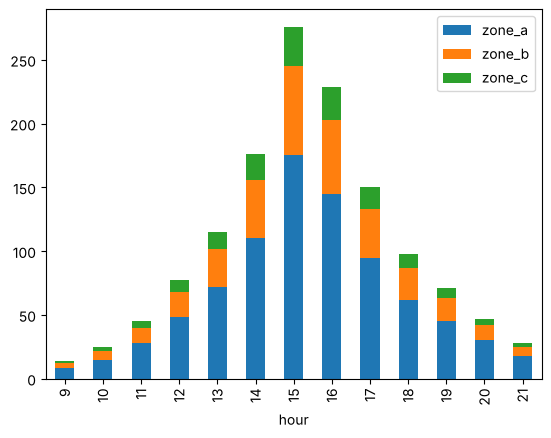

In [9]:
hourly = pd.DataFrame({
    'hour': list(range(9, 22)),
    'zone_a': [8, 15, 28, 48, 72, 110, 175, 145, 95, 62, 45, 30, 18],
    'zone_b': [4, 7, 12, 20, 30, 46, 70, 58, 38, 25, 18, 12, 7],
    'zone_c': [2, 3, 5, 9, 13, 20, 31, 26, 17, 11, 8, 5, 3],
}).set_index('hour')

hourly.plot(kind='bar', stacked=True)
plt.show()

FAIL - title states a finding
FAIL - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 2/6


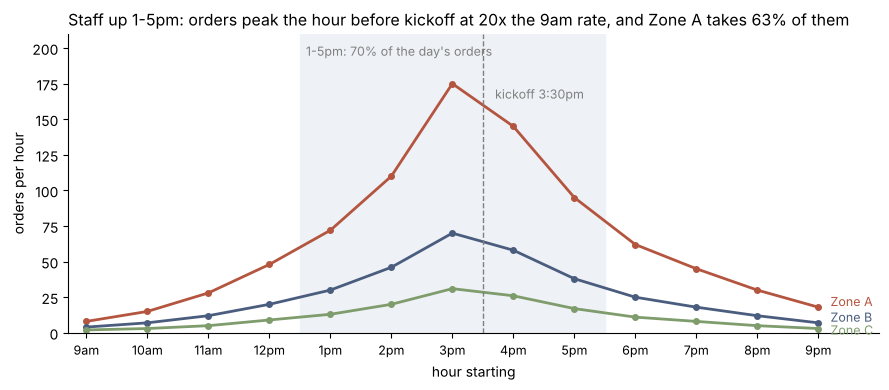

peak hour 15:00 (276 orders) vs 9am (14); Zone A share 63%
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [10]:
score(title=False,       # no title
      axes=False,        # x is "hour" with no am/pm; y has no label or unit
      chart_type=False,  # stacked bars for a trend: only Zone A sits on a common baseline,
                         # B and C float on top of it, so their shapes cannot be compared
      scale=True,        # starts at zero, nothing truncated
      readable=False,    # sideways 24h numbers with no am/pm, raw column names in the legend
      ink=True)

share_a = hourly['zone_a'].sum() / hourly.sum().sum()
peak_hour = hourly.sum(axis=1).idxmax()
peak_total, quiet_total = hourly.sum(axis=1).max(), hourly.sum(axis=1).loc[9]
rush = hourly.loc[13:17]                                     # 1pm-5pm
rush_share = rush.sum().sum() / hourly.sum().sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(12.5, 17.5, color='#eef1f5', zorder=0)
ax.text(12.6, hourly['zone_a'].max() * 1.1, f'1-5pm: {rush_share:.0%} of the day\'s orders',
        fontsize=9, color='gray', va='bottom')
styles = {'zone_a': ('Zone A', '#b4553f'), 'zone_b': ('Zone B', '#4a5d7e'), 'zone_c': ('Zone C', '#7f9c6c')}
nudge = {'zone_a': 4, 'zone_b': 4, 'zone_c': -1}   # keep end labels from overlapping
for col, (label, color) in styles.items():
    ax.plot(hourly.index, hourly[col], marker='o', ms=4, lw=2, color=color)
    ax.text(21.2, hourly[col].iloc[-1] + nudge[col], label, color=color, fontsize=9, va='center')  # direct labels, no legend
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.annotate('kickoff 3:30pm', xy=(15.5, hourly['zone_a'].max()), xytext=(15.7, hourly['zone_a'].max() * 0.94),
            fontsize=9, color='gray')
ax.set_xticks(hourly.index)
ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in hourly.index], fontsize=9)
ax.set_xlim(8.7, 22)
ax.set_ylim(0, hourly['zone_a'].max() * 1.2)
ax.set_xlabel('hour starting')
ax.set_ylabel('orders per hour')
ax.set_title(f'Staff up 1-5pm: orders peak the hour before kickoff at {peak_total / quiet_total:.0f}x the 9am rate, '
             f'and Zone A takes {share_a:.0%} of them', loc='left', fontsize=11.5)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(f'peak hour {peak_hour}:00 ({peak_total} orders) vs 9am ({quiet_total}); Zone A share {share_a:.0%}')
score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

### Your own work

**TODO:** open your midterm notebook, pick the chart you were least happy with, and paste it below. Score it with the rubric, then do one iteration.

If your midterm chart already scores 6, take the one you were *most* happy with and try to make the claim sharper instead.

PASS - title states a finding
PASS - axes labeled with units
FAIL - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 4/6

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6



join: 360 store-days, all matched; best lag +2 days, wind r = +0.80 (spearman +0.25, n = 28 days)


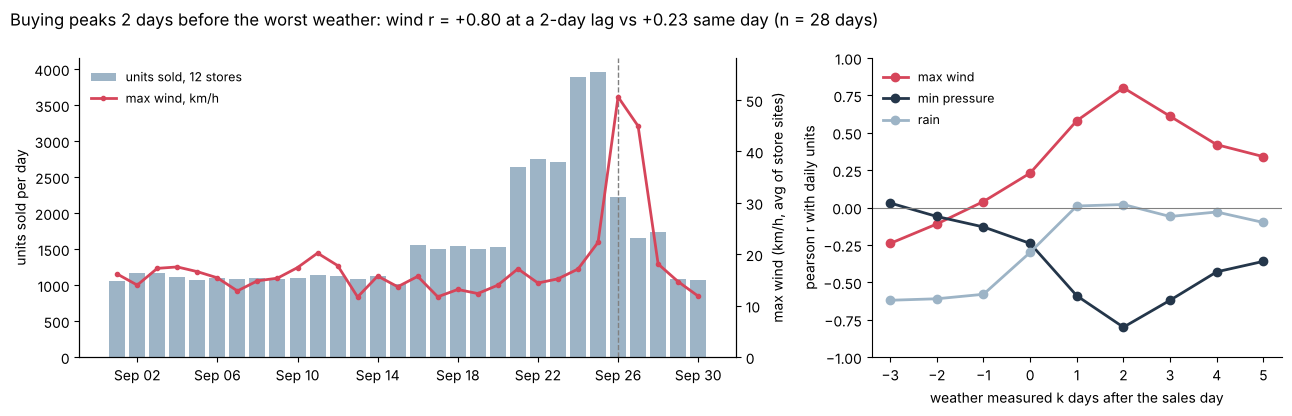

PASS - title states a finding
PASS - axes labeled with units
FAIL - right chart for the question
FAIL - honest scale
FAIL - readable
FAIL - no wasted ink

score: 2/6


2

In [11]:
# My midterm charts are the three in the 2026-10-30 Midterm Progress lab:
score(title=True, axes=True, chart_type=False, scale=True, readable=False, ink=True)   # Q1: five tangled indexed lines for a ranking claim
print()
score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)     # Q2: before/after SKU bars, shared x-axis, Pop-Tarts highlighted
print()
# Q3, the weather chart, is the one I was least happy with. Rebuild its data exactly as the lab did
# (pinned team data, live Open-Meteo archive, Eastern-time days, validated one-to-one join).
import time
import matplotlib.dates as mdates, requests

TEAM_DATA = 'https://raw.githubusercontent.com/ayanrasulova/ds2002-midterm/fd1583a/data'
raw = pd.read_csv(f'{TEAM_DATA}/walmart_transactions.csv', dtype='string', keep_default_na=False)
raw_stores = pd.read_csv(f'{TEAM_DATA}/store_locations.csv', dtype='string', keep_default_na=False)

MISSING_TOKENS = {'', 'NULL', 'N/A', 'NA', 'NAN', 'NONE'}
def normalize_missing(frame):
    out = frame.copy()
    for col in out.columns:
        v = out[col].astype('string').str.strip()
        out[col] = v.mask(v.str.upper().isin(MISSING_TOKENS), pd.NA)
    return out

def normalize_store_id(values):
    text = values.astype('string').str.strip().str.upper()
    parts = text.str.extract(r'^FL[\s_-]?(\d{3})$', expand=False)
    return text.where(parts.isna(), 'FL-' + parts)

def to_number(values):
    return pd.to_numeric(values.astype('string').str.strip().str.replace(r'[$,~]', '', regex=True), errors='coerce')

tx = normalize_missing(raw)
tx['transaction_id'] = tx['transaction_id'].str.strip().str.upper()
tx = tx.drop_duplicates(subset=['transaction_id'], keep='first').copy()
tx['store_id'] = normalize_store_id(tx['store_id'])
tx['quantity'] = to_number(tx['quantity'])
ts = pd.to_datetime(tx['timestamp'], format='mixed', errors='coerce')
tx['timestamp_local'] = ts.dt.tz_localize('America/New_York', ambiguous='NaT', nonexistent='NaT')
tx = tx.loc[~tx['quantity'].lt(0).fillna(False)]
assert len(tx) == 25_402, 'clean row count differs from the midterm'

sales = tx.dropna(subset=['timestamp_local']).copy()
sales['date'] = sales['timestamp_local'].dt.tz_localize(None).dt.normalize()
LANDFALL = pd.Timestamp('2024-09-26')
assert sales.groupby('date')['quantity'].sum().idxmax() == pd.Timestamp('2024-09-25'), 'wrong data version'

stores = normalize_missing(raw_stores)
stores['store_id'] = normalize_store_id(stores['store_id'])
stores['latitude'] = to_number(stores['latitude'])
stores['longitude'] = to_number(stores['longitude'])
stores = stores.drop_duplicates(subset=['store_id'], keep='first').reset_index(drop=True)
coords = stores[['store_id', 'latitude', 'longitude']].copy()
coords.loc[coords['store_id'].eq('FL-619') & coords['latitude'].isna(), ['latitude', 'longitude']] = [30.4383, -84.2807]
assert coords[['latitude', 'longitude']].notna().all().all()

# same Open-Meteo archive call as the midterm lab (one request, 12 stores, UTC -> Eastern)
params = {'latitude': ','.join(coords['latitude'].astype(str)),
          'longitude': ','.join(coords['longitude'].astype(str)),
          'start_date': '2024-09-01', 'end_date': '2024-10-01',
          'hourly': 'precipitation,wind_speed_10m,pressure_msl', 'timezone': 'GMT'}
for attempt in range(1, 4):
    try:
        resp = requests.get('https://archive-api.open-meteo.com/v1/archive', params=params, timeout=30)
        if resp.status_code in {429, 500, 502, 503, 504} and attempt < 3:
            time.sleep(2 ** attempt); continue
        resp.raise_for_status(); break
    except (requests.ConnectionError, requests.Timeout):
        if attempt == 3: raise
        time.sleep(2 ** attempt)
locations = resp.json()
assert len(locations) == len(coords)
frames = []
for store_id, lat, loc in zip(coords['store_id'], coords['latitude'], locations):
    assert abs(loc['latitude'] - lat) < 0.5, f'location order mismatch at {store_id}'
    frames.append(pd.DataFrame(loc['hourly']).assign(store_id=store_id))
wx = pd.concat(frames, ignore_index=True)
wx['time_utc'] = pd.to_datetime(wx['time']).dt.tz_localize('UTC')
wx = wx.sort_values(['store_id', 'time_utc'])
wx['date'] = wx['time_utc'].dt.tz_convert('America/New_York').dt.tz_localize(None).dt.normalize()
wx['rain_in_hour'] = wx.groupby('store_id')['precipitation'].shift(-1)
weather_daily = wx.groupby(['store_id', 'date'], as_index=False).agg(
    precipitation_mm=('rain_in_hour', 'sum'), max_wind_kmh=('wind_speed_10m', 'max'),
    min_pressure_hpa=('pressure_msl', 'min'), hours=('time_utc', 'size'))
weather_daily = weather_daily[weather_daily['date'].between('2024-09-01', '2024-09-30')]
assert weather_daily['hours'].eq(24).all()

store_day = sales.groupby(['store_id', 'date'], as_index=False)['quantity'].sum().rename(columns={'quantity': 'units'})
joined = store_day.merge(weather_daily, on=['store_id', 'date'], how='left', validate='one_to_one', indicator=True)
assert len(joined) == len(store_day) == 360 and joined['_merge'].eq('both').all()
WEATHER_COLUMNS = {'max_wind_kmh': 'max wind', 'min_pressure_hpa': 'min pressure', 'precipitation_mm': 'rain'}
statewide = joined.groupby('date').agg(units=('units', 'sum'), **{c: (c, 'mean') for c in WEATHER_COLUMNS})

def lagged_corr(k, column, method='pearson'):
    shifted = statewide[column].shift(-k)
    keep = shifted.notna()
    return statewide.loc[keep, 'units'].corr(shifted[keep], method=method), int(keep.sum())

lag_table = pd.DataFrame([
    {'lag_days': k, 'n_days': lagged_corr(k, 'max_wind_kmh')[1],
     **{label: lagged_corr(k, col)[0] for col, label in WEATHER_COLUMNS.items()},
     'max wind (spearman)': lagged_corr(k, 'max_wind_kmh', 'spearman')[0]}
    for k in range(-3, 6)]).set_index('lag_days').round(2)
best_lag = int(lag_table['max wind'].idxmax())
assert best_lag == 2 and lag_table.loc[2, 'max wind'] == 0.80, 'lag result differs from the midterm'

print(f'join: {len(joined)} store-days, all matched; best lag +{best_lag} days, wind r = {lag_table.loc[2, "max wind"]:+.2f} '
      f'(spearman {lag_table.loc[2, "max wind (spearman)"]:+.2f}, n = {lag_table.loc[2, "n_days"]} days)')

# ---- BEFORE: the Q3 chart as presented at the midterm ----
fig, (ax, ax_lag) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.6, 1]})
ax.bar(statewide.index, statewide['units'], color='#9db4c6', width=0.8, label='units sold, 12 stores')
ax.set_ylabel('units sold per day')
ax2 = ax.twinx()
ax2.plot(statewide.index, statewide['max_wind_kmh'], color='#d6455a', lw=2, marker='o', ms=3, label='max wind, km/h')
ax2.set_ylim(0, statewide['max_wind_kmh'].max() * 1.15)
ax2.set_ylabel('max wind (km/h, avg of store sites)')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0],
          ['units sold, 12 stores', 'max wind, km/h'], frameon=False, fontsize=9, loc='upper left')
for column, label in WEATHER_COLUMNS.items():
    ax_lag.plot(lag_table.index, lag_table[label], marker='o', lw=2, label=label,
                color={'max wind': '#d6455a', 'min pressure': '#24364a', 'rain': '#9db4c6'}[label])
ax_lag.axhline(0, color='gray', lw=0.8)
ax_lag.set_ylim(-1, 1)
ax_lag.set_xlabel('weather measured k days after the sales day')
ax_lag.set_ylabel('pearson r with daily units')
ax_lag.legend(frameon=False, fontsize=9, loc='upper left')
for axis in (ax, ax2, ax_lag):
    axis.spines['top'].set_visible(False)
ax_lag.spines['right'].set_visible(False)
fig.suptitle(f"Buying peaks {best_lag} days before the worst weather: wind r = "
             f"{lag_table.loc[best_lag, 'max wind']:+.2f} at a {best_lag}-day lag vs "
             f"{lag_table.loc[0, 'max wind']:+.2f} same day (n = {lag_table.loc[best_lag, 'n_days']} days)",
             x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

score(title=True,        # states a finding with numbers
      axes=True,         # both y-axes and the lag axis are labeled with units
      chart_type=False,  # dual y-axis: bars and a line on independent scales invite the reader to read
                         # a relationship off where the two happen to cross
      scale=False,       # where the wind line sits against the bars is set by an arbitrary ax2 ylim
                         # (max * 1.15), not by the data
      readable=False,    # the lag panel asks a manager to decode "weather k days after the sales day"
                         # and Pearson r before the point lands
      ink=False)         # rain and pressure lines are not part of the claim (pressure just mirrors wind)

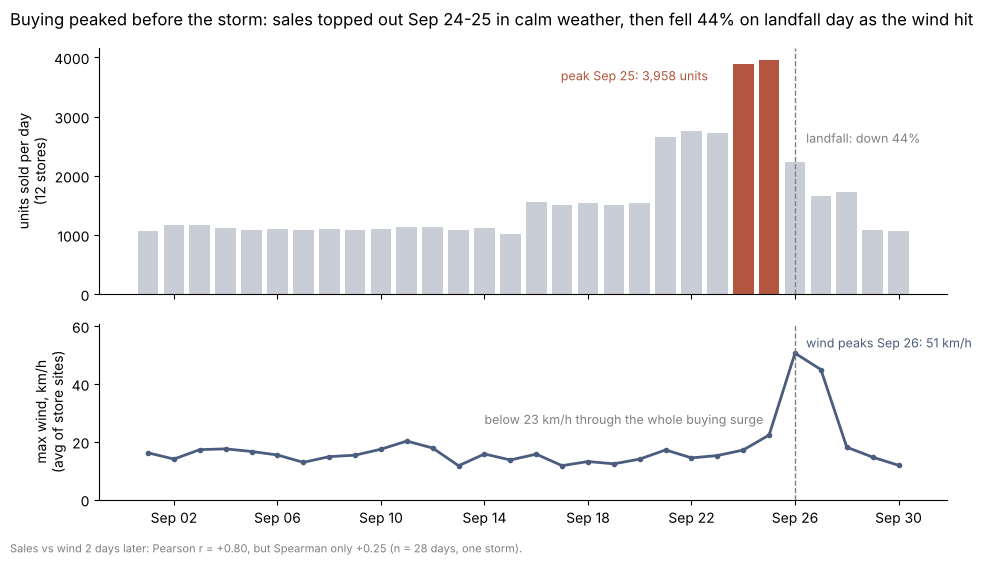

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [12]:
# ---- AFTER: one iteration. Two panels on one shared date axis, each starting at zero, so the
# timing is read off the x-axis instead of off two arbitrary y-scales. Rain, pressure and the
# lag panel are gone; the correlation and its caveat move to a footnote.
peak_sales_day = statewide['units'].idxmax()
peak_wind_day = statewide['max_wind_kmh'].idxmax()
drop = 1 - statewide.loc[LANDFALL, 'units'] / statewide['units'].max()
calm_max = statewide.loc[:peak_sales_day, 'max_wind_kmh'].max()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
colors = ['#b4553f' if d in (peak_sales_day - pd.Timedelta(days=1), peak_sales_day) else '#c9cdd6'
          for d in statewide.index]
top.bar(statewide.index, statewide['units'], color=colors, width=0.8)
top.set_ylabel('units sold per day\n(12 stores)')
top.annotate(f"peak {peak_sales_day:%b %d}: {statewide['units'].max():,.0f} units",
             xy=(peak_sales_day, statewide['units'].max()), xytext=(-150, -6), textcoords='offset points',
             fontsize=9, color='#b4553f', va='top')
top.annotate(f'landfall: down {drop:.0%}', xy=(LANDFALL, statewide.loc[LANDFALL, 'units']),
             xytext=(8, 14), textcoords='offset points', fontsize=9, color='gray')

bottom.plot(statewide.index, statewide['max_wind_kmh'], color='#4a5d7e', lw=2, marker='o', ms=3)
bottom.set_ylim(0, statewide['max_wind_kmh'].max() * 1.2)
bottom.set_ylabel('max wind, km/h\n(avg of store sites)')
bottom.annotate(f"wind peaks {peak_wind_day:%b %d}: {statewide['max_wind_kmh'].max():.0f} km/h",
                xy=(peak_wind_day, statewide['max_wind_kmh'].max()), xytext=(8, 2), textcoords='offset points',
                fontsize=9, color='#4a5d7e', va='bottom')
bottom.annotate(f'below {np.ceil(calm_max):.0f} km/h through the whole buying surge',
                xy=(pd.Timestamp('2024-09-14'), calm_max), xytext=(0, 8), textcoords='offset points',
                fontsize=9, color='gray')
bottom.xaxis.set_major_locator(mdates.DayLocator(interval=4))
bottom.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
for axis in (top, bottom):
    axis.axvline(LANDFALL, ls='--', color='gray', lw=1)
    for spine in ('top', 'right'):
        axis.spines[spine].set_visible(False)

fig.suptitle(f"Buying peaked before the storm: sales topped out {peak_sales_day - pd.Timedelta(days=1):%b %d}-{peak_sales_day:%d} "
             f"in calm weather, then fell {drop:.0%} on landfall day as the wind hit",
             x=0.01, ha='left', fontsize=12)
fig.text(0.01, 0.01, f"Sales vs wind 2 days later: Pearson r = {lag_table.loc[2, 'max wind']:+.2f}, but Spearman only "
         f"{lag_table.loc[2, 'max wind (spearman)']:+.2f} (n = {lag_table.loc[2, 'n_days']} days, one storm).",
         fontsize=8, color='gray')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

score(title=True, axes=True, chart_type=True, scale=True, readable=True, ink=True)

**My score before:** 2/6  **After:** 6/6  **What I changed:** I scored all three charts from the midterm progress lab: Q1 (surge lines) 4/6, Q2 (SKU before/after) 6/6 and Q3 (weather) 2/6, so Q3 is the one I redesigned. The original overlaid sales bars and a wind line on two independent y-axes. Where the wind line sat against the bars was set by an arbitrary `ylim`, and next to it was a lag-correlation panel with rain and pressure lines that are not part of the claim. I split it into two panels on one shared date axis, both starting at zero, and dropped rain, pressure and the lag panel. The peak sales days are highlighted and the peak sales day, the wind peak and the landfall drop are annotated. The title now states what a manager can act on: buying topped out Sept 24–25 while the wind was still under 23 km/h, and fell 44% on landfall day, so the stock has to be in before the weather turns. The r = +0.80 lag result moves to a footnote, next to its caveat (Spearman +0.25, one storm).

---

## Checkpoint (participation)

Report the rubric score of your own midterm chart before and after your redesign, and what you changed.

Work the last few minutes in groups of 4–5, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Wednesday 11:59pm ET**. One submission per person, not per group.

In [13]:
# Checkpoint
chart_i_fixed = 'Q3 weather chart: daily units vs max wind, dual axis + lag panel (2026-10-30 Midterm Progress lab)'
score_before = 2           # failed: right chart type, honest scale, readable, no wasted ink
score_after = 6
new_title = ('Buying peaked before the storm: sales topped out Sep 24-25 in calm weather, '
             f'then fell {drop:.0%} on landfall day as the wind hit')

print('chart:', chart_i_fixed)
print('score:', score_before, '->', score_after)
print('new title:', new_title)

chart: Q3 weather chart: daily units vs max wind, dual axis + lag panel (2026-10-30 Midterm Progress lab)
score: 2 -> 6
new title: Buying peaked before the storm: sales topped out Sep 24-25 in calm weather, then fell 44% on landfall day as the wind hit
